# Notebook 02 - Q4: Phân tích Chuyên sâu Câu hỏi Q4 (Dùng thuốc sai nhãn Off-label & Kết cục y khoa)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) giai đoạn 2025 và Đối chiếu Xu hướng 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm thực hiện:** Global Ban  
**Thành viên phụ trách:** Huỳnh Tuấn Kiệt (M3 — MSSV: `24120356`)  
**Phản biện chéo:** Trần Ngô Uyên Nhi (M2)  
**Liên kết Master Hub:** [Notebook 02: Master Hub (Mục 3.3 Question Formulation & D1–D6)](02_analysis.ipynb)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_processed
from src.preprocessing import (
    KEY,
    load_clean_tables,
    run_core_preprocessing,
    save_clean_tables,
    log_row_count_change,
)
from src.visualization import set_project_plot_style

set_project_plot_style()

In [2]:
# Tải 4 bảng dữ liệu sạch chuẩn hóa từ pipeline tiền xử lý lõi Task T14 (src/preprocessing.py)
RAW_PROC_DIR = PROJECT_ROOT / "data" / "processed"
CLEAN_PROC_DIR = RAW_PROC_DIR / "clean"

raw_tables = load_processed(RAW_PROC_DIR)
if not (CLEAN_PROC_DIR / "reports.csv").exists():
    clean_tables, _ = run_core_preprocessing(raw_tables, verbose=True)
    save_clean_tables(clean_tables, CLEAN_PROC_DIR)
else:
    clean_tables = load_clean_tables(CLEAN_PROC_DIR)

reports = clean_tables["reports"]
drugs = clean_tables["drugs"]
reactions = clean_tables["reactions"]
outcomes = clean_tables["outcomes"]

print("=== ĐỐI CHIẾU QUY MÔ DỮ LIỆU THÔ (data/processed) -> SẠCH LÕI T14 (data/processed/clean) ===")
for name in ("reports", "drugs", "reactions", "outcomes"):
    log_row_count_change(
        f"T14_core_{name}",
        len(raw_tables[name]),
        len(clean_tables[name]),
        "Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)",
    )
print(
    f"\n[Clean Data Ready] Reports: {reports.shape}, Drugs: {drugs.shape}, "
    f"Reactions: {reactions.shape}, Outcomes: {outcomes.shape}"
)

=== ĐỐI CHIẾU QUY MÔ DỮ LIỆU THÔ (data/processed) -> SẠCH LÕI T14 (data/processed/clean) ===
[T14_core_reports] Rows: 94,412 -> 93,812 (Change: -600 | -0.64%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_drugs] Rows: 174,123 -> 173,221 (Change: -902 | -0.52%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_reactions] Rows: 270,244 -> 267,848 (Change: -2,396 | -0.89%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)
[T14_core_outcomes] Rows: 85,143 -> 84,543 (Change: -600 | -0.70%) | Reason: Làm sạch lõi T14 (loại ca Human, chuẩn hóa thiếu ẩn/ngày/sinh trắc học, khử trùng lặp reactions)

[Clean Data Ready] Reports: (93812, 53), Drugs: (173221, 31), Reactions: (267848, 8), Outcomes: (84543, 6)


---
## Câu hỏi Q4: Sử dụng Thuốc Sai Nhãn (Off-label), Đa Trị Liệu & Mức độ Nghiêm Trọng / Kết Cục

### Phát biểu câu hỏi và Động lực
- **Phát biểu câu hỏi:**  
  > **"Việc dùng thuốc off-label kết hợp với đa trị liệu (`polypharmacy`) trong năm 2025 có liên hệ như thế nào với mức độ nghiêm trọng (`serious_ae`) và kết quả lâm sàng (`outcome`) khi đã kiểm soát biến nhiễu là loài vật nuôi và đối tượng báo cáo (`primary_reporter`)?"**
- **Người quan tâm & Quyết định hỗ trợ (Target Users & Decisions):**
  - **Hiệp hội Bác sĩ Thú y Lâm sàng (AVMA) & Cơ quan Quản lý Dược (FDA CVM — AMDUCA Regulation):** Theo Đạo luật Làm rõ Việc Sử dụng Thuốc Ngoài Nhãn trong Thú y (*Animal Medicinal Drug Use Clarification Act — AMDUCA*), bác sĩ thú y được phép kê đơn *extra-label / off-label* (đổi liều, đổi loài, đổi chỉ định hoặc phối hợp đa thuốc) khi không có thuốc chuẩn thuận phù hợp. Tuy nhiên, việc định lượng **mức gia tăng rủi ro biến cố nghiêm trọng và tử vong/an tử** khi kết hợp *Off-label* với *Đa trị liệu (`num_drugs >= 2`)* là bằng chứng quyết định để thiết lập cảnh báo tương tác thuốc và quy trình giám sát hậu điều trị.
- **Tiêu chí độ sâu áp dụng (Mục 3.3 — bao phủ 4 tiêu chí D1, D3, D4, D6):**
  - **`D1` (Combining data):** Tích hợp 3 bảng sạch từ Task T14 (`reports`, `drugs`, `outcomes`) ở cấp độ báo cáo duy nhất (`unique_aer_id_number`), bảo đảm không nhân bản dòng khi một ca bệnh có nhiều thuốc và nhiều kết cục.
  - **`D3` (Derived variables):** Xây dựng các biến dẫn xuất cấp báo cáo có cơ sở lâm sàng:
    1. `label_status` (`On-label Only`, `Off-label`, `Missing/Unknown`) tổng hợp từ cả hai cột `used_according_to_label` và `off_label_use` của tất cả thuốc trong ca bệnh.
    2. `is_polypharmacy` ($\ge 2$ thuốc vs. $1$ thuốc), `poly_tier` (`1 thuốc`, `2 thuốc`, `>= 3 thuốc`), và biến tổ hợp tương tác 4 nhóm `regimen_4` (`On-label × 1 thuốc`, `On-label × >=2 thuốc`, `Off-label × 1 thuốc`, `Off-label × >=2 thuốc`).
    3. `worst_outcome_rank` & `is_fatal`: Phân cấp thứ bậc kết cục xấu nhất của ca bệnh (`3: Fatal [Died / Euthanized]` $>$ `2: Non-Recovered [Ongoing / Sequela]` $>$ `1: Recovered / Normal` $>$ `0: Outcome Unknown / Unreported`).
  - **`D4` (Controlling for a confounder):** Kiểm soát đồng thời hai biến nhiễu trọng yếu là **Loài vật nuôi (`species_group`: `Dog`, `Cat`, `Other`)** và **Đối tượng báo cáo (`reporter_group`: `Veterinarian`, `Animal Owner`, `Other HCP`)** bằng cả **Phân tầng Cochran–Mantel–Haenszel ($\text{aOR}_{\text{MH}}$)** lẫn **Hồi quy Logistic Đa biến có số hạng tương tác ($\text{Off-label} \times \text{Polypharmacy}$)**.
  - **`D6` (Robustness check):** Kiểm tra độ vững của kết luận qua **9 kịch bản độ nhạy (Sensitivity Scenarios)**: (S1) Complete-case chuẩn; (S2) Quy nhóm khuyết nhãn `'Missing/Unknown'` về `'On-label'`; (S3) Lọc bỏ các ca đa trị liệu ngoại lai vượt ngưỡng IQR (`num_drugs <= 3`); (S4) Tách riêng **Tử vong tự nhiên (`Died` only)** khỏi **An tử nhân đạo (`Euthanized`)**; và (S5) Mở rộng kiểm chứng trên tập dữ liệu **Out-of-Time 2026 Q1**.

### 1. Tiền xử lý cho Q4

Quy trình tiền xử lý chuyên biệt cho Q4 kế thừa 4 bảng sạch từ **Task T14 (`data/processed/clean/`)** và thực hiện 4 bước tổng hợp – lọc có theo dõi số dòng (`log_row_count_change`):

1. **Bước 1.1 — Lọc tập báo cáo thú y năm 2025 (`2025q1`–`2025q4`):**
   - Từ `93,812` báo cáo thú y sạch (5 quý), lọc giữ `76,630` báo cáo thuộc 4 quý năm 2025.
2. **Bước 1.2 — Tổng hợp trạng thái tuân thủ nhãn thuốc (`label_status`) và chi tiết hành vi sai nhãn từ bảng `drugs` (D1 & D3):**
   - Gộp `141,585` dòng thuốc năm 2025 về đúng `76,630` báo cáo cha:
     - Gán **`Off-label`** nếu báo cáo có ít nhất 1 thuốc ghi nhận `used_according_to_label == 'false'` hoặc có mô tả hành vi sai nhãn cụ thể tại `off_label_use` (`Treatment regimen Off-Label`, `Indication Off-Label`, `Overdosed`, `Underdosed`, `Species Off-Label`, `Route Off-Label`...).
     - Gán **`On-label Only`** nếu báo cáo không có thuốc nào dùng sai nhãn và có ít nhất 1 thuốc xác nhận `used_according_to_label == 'true'`.
     - Gán **`Missing/Unknown`** nếu toàn bộ thuốc trong báo cáo đều khuyết thông tin nhãn (giữ riêng để phân tích cơ chế khuyết MAR/MNAR và chạy kiểm định độ nhạy **D6**).
3. **Bước 1.3 — Tổng hợp thứ bậc kết cục lâm sàng xấu nhất (`worst_outcome_rank`) từ bảng `outcomes` (D1 & D3):**
   - Gộp `69,034` dòng kết cục năm 2025 về cấp báo cáo theo quy tắc ưu tiên kết cục trầm trọng nhất: `Rank 3 (Fatal: Died / Euthanized)` $>$ `Rank 2 (Non-Recovered: Ongoing / Sequela)` $>$ `Rank 1 (Recovered / Normal)` $>$ `Rank 0 (Outcome Unknown / Unreported)`.
   - Đồng thời tạo cờ tách biệt `is_died_natural` (`medical_status == 'Died'`) và `is_euthanized` (`medical_status == 'Euthanized'`) phục vụ kiểm định độ nhạy **D6**.
4. **Bước 1.4 — Trích xuất các tập phân tích chuyên biệt (Complete-case & Sensitivity Cohorts):**
   - Tập đánh giá mức độ nghiêm trọng (`serious` xác định `0/1`): `68,340` báo cáo (trong đó `50,588` báo cáo xác định rõ nhãn `On-label Only` vs. `Off-label`).
   - Tập đánh giá kết cục lâm sàng (`worst_outcome_rank > 0`): `47,645` báo cáo biết kết cục (trong đó `36,709` báo cáo xác định đồng thời cả nhãn thuốc và kết cục).

In [3]:
# ===== 1. Thực thi Tiền xử lý chuyên biệt cho Q4 kèm log_row_count_change =====
QUARTERS_2025 = ("2025q1", "2025q2", "2025q3", "2025q4")

# Bước 1.1: Lọc báo cáo năm 2025
rep_q4_base = reports[reports["quarter"].isin(QUARTERS_2025)].copy()
log_row_count_change(
    "Q4_step1_filter_2025_reports",
    len(reports),
    len(rep_q4_base),
    "Lọc báo cáo thú y thuộc 4 quý năm 2025 (2025q1-2025q4)",
)

# Bước 1.2: Tổng hợp trạng thái nhãn thuốc & hành vi off-label từ bảng drugs về cấp báo cáo (D1 & D3)
drg_q4 = drugs[drugs[KEY].isin(rep_q4_base[KEY])].copy()
log_row_count_change(
    "Q4_step2a_sync_drugs_2025",
    len(drugs),
    len(drg_q4),
    "Đồng bộ bảng drugs với tập báo cáo năm 2025",
)

drg_q4["is_off_label_drug"] = (
    drg_q4["used_according_to_label"].eq("false")
    | drg_q4["off_label_use"].notna()
)
drg_q4["is_on_label_drug"] = (
    drg_q4["used_according_to_label"].eq("true")
    & (~drg_q4["is_off_label_drug"])
)

drug_label_agg = drg_q4.groupby(KEY).agg(
    n_drug_rows=("drug_idx", "size"),
    n_off_label_drugs=("is_off_label_drug", "sum"),
    any_off_label=("is_off_label_drug", "any"),
    any_on_label=("is_on_label_drug", "any"),
)
drug_label_agg["label_status"] = np.where(
    drug_label_agg["any_off_label"],
    "Off-label",
    np.where(drug_label_agg["any_on_label"], "On-label Only", "Missing/Unknown"),
)
log_row_count_change(
    "Q4_step2b_aggregate_drugs_to_report",
    len(drg_q4),
    len(drug_label_agg),
    "Tổng hợp trạng thái nhãn thuốc từ cấp dòng thuốc (N:1) về cấp báo cáo duy nhất (1:1)",
)

# Bước 1.3: Tổng hợp thứ bậc kết cục lâm sàng xấu nhất từ bảng outcomes về cấp báo cáo (D1 & D3)
out_q4 = outcomes[outcomes[KEY].isin(rep_q4_base[KEY])].copy()
log_row_count_change(
    "Q4_step3a_sync_outcomes_2025",
    len(outcomes),
    len(out_q4),
    "Đồng bộ bảng outcomes với tập báo cáo năm 2025",
)

OUTCOME_RANK_MAP = {
    "Died": 3,
    "Euthanized": 3,
    "Ongoing": 2,
    "Recovered with Sequela": 2,
    "Recovered/Normal": 1,
    "Outcome Unknown": 0,
}
out_q4["outcome_rank"] = out_q4["medical_status"].map(OUTCOME_RANK_MAP).fillna(0).astype(int)
out_q4["is_died_natural"] = out_q4["medical_status"].eq("Died")
out_q4["is_euthanized"] = out_q4["medical_status"].eq("Euthanized")

outcome_rep_agg = out_q4.groupby(KEY).agg(
    worst_outcome_rank=("outcome_rank", "max"),
    any_died_natural=("is_died_natural", "any"),
    any_euthanized=("is_euthanized", "any"),
)
log_row_count_change(
    "Q4_step3b_aggregate_outcomes_to_report",
    len(out_q4),
    len(outcome_rep_agg),
    "Tổng hợp kết cục y khoa xấu nhất (worst_outcome_rank) từ bảng outcomes về cấp báo cáo",
)

# Bước 1.4: Kết nối bảng phân tích Q4 cấp báo cáo và tạo biến dẫn xuất D3
q4_cols_rep = [KEY, "quarter", "species", "species_group", "primary_reporter", "type_of_information", "serious", "num_drugs"]
q4_df = (
    rep_q4_base[q4_cols_rep]
    .merge(drug_label_agg, on=KEY, how="left")
    .merge(outcome_rep_agg, on=KEY, how="left")
)
q4_df["label_status"] = q4_df["label_status"].fillna("Missing/Unknown")
q4_df["worst_outcome_rank"] = q4_df["worst_outcome_rank"].fillna(0).astype(int)
q4_df["any_died_natural"] = q4_df["any_died_natural"].fillna(False)
q4_df["any_euthanized"] = q4_df["any_euthanized"].fillna(False)

q4_df["is_fatal"] = (q4_df["worst_outcome_rank"] == 3).astype(int)
q4_df["is_died_only"] = q4_df["any_died_natural"].astype(int)
q4_df["is_polypharmacy"] = (q4_df["num_drugs"].fillna(0) >= 2).astype(int)
q4_df["poly_tier"] = np.where(
    q4_df["num_drugs"] >= 3,
    "3. >=3 thuốc (High Polypharmacy)",
    np.where(q4_df["num_drugs"] == 2, "2. 2 thuốc (Moderate Poly)", "1. 1 thuốc (Monotherapy)"),
)
q4_df["reporter_group"] = np.where(
    q4_df["primary_reporter"].eq("Veterinarian"),
    "Veterinarian",
    np.where(q4_df["primary_reporter"].eq("Animal Owner"), "Animal Owner", "Other HCP / Reporter"),
)
OUTCOME_RANK_LABELS = {
    3: "3. Fatal (Died / Euthanized)",
    2: "2. Non-Recovered (Ongoing / Sequela)",
    1: "1. Recovered / Normal",
    0: "0. Outcome Unknown / Unreported",
}
q4_df["worst_outcome_label"] = q4_df["worst_outcome_rank"].map(OUTCOME_RANK_LABELS)

# Các tập con phục vụ phân tích chính và kiểm định độ nhạy D6
q4_serious_all = q4_df.dropna(subset=["serious"]).copy()
q4_serious_all["serious_int"] = q4_serious_all["serious"].astype(int)
log_row_count_change(
    "Q4_step4a_filter_known_serious",
    len(q4_df),
    len(q4_serious_all),
    "Lọc báo cáo có nhãn mức độ nghiêm trọng xác định (serious in {0, 1})",
)

q4_serious_known_lbl = q4_serious_all[q4_serious_all["label_status"].isin(["On-label Only", "Off-label"])].copy()
q4_serious_known_lbl["is_off_label"] = q4_serious_known_lbl["label_status"].eq("Off-label").astype(int)
log_row_count_change(
    "Q4_step4b_serious_complete_case_label",
    len(q4_serious_all),
    len(q4_serious_known_lbl),
    "Lọc tập Complete-case có trạng thái nhãn thuốc xác định (On-label Only vs. Off-label) cho mô hình serious_ae",
)

q4_outcome_known = q4_df[q4_df["worst_outcome_rank"] > 0].copy()
log_row_count_change(
    "Q4_step4c_filter_known_outcome",
    len(q4_df),
    len(q4_outcome_known),
    "Lọc báo cáo có kết cục lâm sàng xác định (worst_outcome_rank in {1, 2, 3})",
)

q4_outcome_known_lbl = q4_outcome_known[q4_outcome_known["label_status"].isin(["On-label Only", "Off-label"])].copy()
q4_outcome_known_lbl["is_off_label"] = q4_outcome_known_lbl["label_status"].eq("Off-label").astype(int)
log_row_count_change(
    "Q4_step4d_outcome_complete_case_label",
    len(q4_outcome_known),
    len(q4_outcome_known_lbl),
    "Lọc tập Complete-case xác định đồng thời cả nhãn thuốc và kết cục y khoa cho mô hình tử vong/hồi phục",
)

q4_overview = (
    q4_df.groupby(["label_status", "is_polypharmacy"])
    .agg(
        total_reports=(KEY, "count"),
        n_known_serious=("serious", lambda s: s.notna().sum()),
        serious_rate_pct=("serious", lambda s: s.dropna().astype(int).mean() * 100),
        n_known_outcome=("worst_outcome_rank", lambda s: (s > 0).sum()),
        fatal_rate_known_pct=("is_fatal", lambda s: s[q4_df.loc[s.index, "worst_outcome_rank"] > 0].mean() * 100),
        recovered_rate_known_pct=("worst_outcome_rank", lambda s: (s[s > 0] == 1).mean() * 100),
    )
    .reset_index()
)
q4_overview["Phác đồ đa trị liệu"] = np.where(q4_overview["is_polypharmacy"] == 1, "Polypharmacy (>=2 thuốc)", "Monotherapy (1 thuốc)")
q4_overview = q4_overview[["label_status", "Phác đồ đa trị liệu", "total_reports", "n_known_serious", "serious_rate_pct", "n_known_outcome", "fatal_rate_known_pct", "recovered_rate_known_pct"]]
print("\n=== BẢNG TỔNG HỢP TỶ LỆ NGHIÊM TRỌNG & KẾT CỤC LÂM SÀNG THEO NHÃN THUỐC × ĐA TRỊ LIỆU (2025) ===")
display(
    q4_overview.style.format({
        "total_reports": "{:,}", "n_known_serious": "{:,}", "serious_rate_pct": "{:.2f}%",
        "n_known_outcome": "{:,}", "fatal_rate_known_pct": "{:.2f}%", "recovered_rate_known_pct": "{:.2f}%"
    })
)

[Q4_step1_filter_2025_reports] Rows: 93,812 -> 76,630 (Change: -17,182 | -18.32%) | Reason: Lọc báo cáo thú y thuộc 4 quý năm 2025 (2025q1-2025q4)


[Q4_step2a_sync_drugs_2025] Rows: 173,221 -> 141,585 (Change: -31,636 | -18.26%) | Reason: Đồng bộ bảng drugs với tập báo cáo năm 2025
[Q4_step2b_aggregate_drugs_to_report] Rows: 141,585 -> 76,630 (Change: -64,955 | -45.88%) | Reason: Tổng hợp trạng thái nhãn thuốc từ cấp dòng thuốc (N:1) về cấp báo cáo duy nhất (1:1)


[Q4_step3a_sync_outcomes_2025] Rows: 84,543 -> 69,034 (Change: -15,509 | -18.34%) | Reason: Đồng bộ bảng outcomes với tập báo cáo năm 2025
[Q4_step3b_aggregate_outcomes_to_report] Rows: 69,034 -> 68,617 (Change: -417 | -0.60%) | Reason: Tổng hợp kết cục y khoa xấu nhất (worst_outcome_rank) từ bảng outcomes về cấp báo cáo
[Q4_step4a_filter_known_serious] Rows: 76,630 -> 68,340 (Change: -8,290 | -10.82%) | Reason: Lọc báo cáo có nhãn mức độ nghiêm trọng xác định (serious in {0, 1})


[Q4_step4b_serious_complete_case_label] Rows: 68,340 -> 50,588 (Change: -17,752 | -25.98%) | Reason: Lọc tập Complete-case có trạng thái nhãn thuốc xác định (On-label Only vs. Off-label) cho mô hình serious_ae
[Q4_step4c_filter_known_outcome] Rows: 76,630 -> 47,645 (Change: -28,985 | -37.82%) | Reason: Lọc báo cáo có kết cục lâm sàng xác định (worst_outcome_rank in {1, 2, 3})
[Q4_step4d_outcome_complete_case_label] Rows: 47,645 -> 36,709 (Change: -10,936 | -22.95%) | Reason: Lọc tập Complete-case xác định đồng thời cả nhãn thuốc và kết cục y khoa cho mô hình tử vong/hồi phục

=== BẢNG TỔNG HỢP TỶ LỆ NGHIÊM TRỌNG & KẾT CỤC LÂM SÀNG THEO NHÃN THUỐC × ĐA TRỊ LIỆU (2025) ===


,label_status,Phác đồ đa trị liệu,total_reports,n_known_serious,serious_rate_pct,n_known_outcome,fatal_rate_known_pct,recovered_rate_known_pct
0,Missing/Unknown,Monotherapy (1 thuốc),"20,656","12,523",34.74%,"7,303",15.19%,23.96%
1,Missing/Unknown,Polypharmacy (>=2 thuốc),"5,354","5,229",47.58%,"3,633",20.62%,20.84%
2,Off-label,Monotherapy (1 thuốc),"8,404","8,385",47.27%,"6,285",5.78%,18.84%
3,Off-label,Polypharmacy (>=2 thuốc),"7,287","7,274",54.33%,"5,386",15.60%,24.73%
4,On-label Only,Monotherapy (1 thuốc),"21,512","21,512",34.75%,"15,086",3.94%,32.10%
5,On-label Only,Polypharmacy (>=2 thuốc),"13,417","13,417",47.57%,"9,952",13.28%,26.83%


### 2. Phương pháp phân tích

1. **Phân tầng Cochran–Mantel–Haenszel kiểm soát đồng thời Loài & Đối tượng báo cáo (Tiêu chí D4):**
   - Thiết lập $3 \times 3 = 9$ tầng kết hợp giữa `species_group` ($\{\text{Dog}, \text{Cat}, \text{Other}\}$) và `reporter_group` ($\{\text{Veterinarian}, \text{Animal Owner}, \text{Other HCP}\}$).
   - Ước lượng **Tỷ số chênh hiệu chỉnh Mantel–Haenszel ($\text{aOR}_{\text{MH}}$)** và khoảng tin cậy 95% Robins–Breslow–Greenland cho tác động của `Off-label` và `Polypharmacy` lên cả hai đầu ra: (1) Biến cố nghiêm trọng (`serious_ae = True`) và (2) Kết cục tử vong/an tử (`is_fatal = 1`).
2. **Hồi quy Logistic Đa biến có Số hạng Tương tác ($\text{Off-label} \times \text{Polypharmacy}$) (Tiêu chí D3 & D4):**
   - Giải hệ phương trình hợp lý cực đại bằng thuật toán **Newton–Raphson / IRLS (Iteratively Reweighted Least Squares)** hội tụ chính xác đến $10^{-8}$, trích xuất ma trận hiệp phương sai tiệm cận $\mathbf{\Sigma} = (\mathbf{X}^T \mathbf{W} \mathbf{X})^{-1}$:
     $$\text{logit}\big(P(Y_i = 1)\big) = \beta_0 + \beta_1 \,\text{OffLabel}_i + \beta_2 \,\text{Poly}_i + \beta_3 (\text{OffLabel}_i \times \text{Poly}_i) + \boldsymbol{\gamma}^T \mathbf{S}_i + \boldsymbol{\delta}^T \mathbf{R}_i$$
   - Trong đó $\mathbf{S}_i$ là vector biến giả loài (`Cat`, `Other` so với `Dog`) và $\mathbf{R}_i$ là vector biến giả đối tượng báo cáo (`Animal Owner`, `Other HCP` so với `Veterinarian`).
   - Từ các hệ số $\hat{\beta}_1, \hat{\beta}_2, \hat{\beta}_3$ và ma trận $\mathbf{\Sigma}$, tính trực tiếp **Tỷ số chênh kết hợp (Joint Adjusted Odds Ratio)** của phác đồ nguy cơ cao nhất (`Off-label + Polypharmacy` so với nhóm tham chiếu `On-label + Monotherapy`):
     $$\text{aOR}_{\text{joint}} = \exp(\hat{\beta}_1 + \hat{\beta}_2 + \hat{\beta}_3), \qquad \text{Var}(\hat{\beta}_{\text{joint}}) = \mathbf{c}^T \mathbf{\Sigma} \mathbf{c}$$
3. **Kiểm định Độ vững & Phân tích Độ nhạy 9 Kịch bản (Tiêu chí D6):**
   - Đánh giá xem chiều hướng và ý nghĩa thống kê của $\text{aOR}_{\text{Off-label}}$, $\text{aOR}_{\text{Poly}}$ và $\text{aOR}_{\text{joint}}$ có bất biến qua các kịch bản xử lý dữ liệu khuyết (`Missing/Unknown`), cắt lọc ngoại lai đa trị liệu (`num_drugs <= 3`), tách tử vong tự nhiên (`Died` only), và kiểm thử trên tập **Out-of-Time 2026 Q1** hay không.

In [4]:
# ===== 2. Thực thi Phân tầng Mantel-Haenszel (D4), Hồi quy Logistic Đa biến có Tương tác (D4), và Kiểm định Độ vững 9 Kịch bản (D6) =====

def compute_cmh_adjusted_or(df_in: pd.DataFrame, exp_col: str, out_col: str, strata_cols: list) -> dict:
    """Tính Crude OR và Cochran-Mantel-Haenszel Adjusted OR qua các tầng biến nhiễu."""
    a = float(((df_in[exp_col] == 1) & (df_in[out_col] == 1)).sum())
    b = float(((df_in[exp_col] == 1) & (df_in[out_col] == 0)).sum())
    c = float(((df_in[exp_col] == 0) & (df_in[out_col] == 1)).sum())
    d = float(((df_in[exp_col] == 0) & (df_in[out_col] == 0)).sum())
    crude_or = (a * d) / (b * c)
    se_crude = np.sqrt(1.0 / a + 1.0 / b + 1.0 / c + 1.0 / d)

    num_mh, den_mh, G_t, H_t, FG_t = 0.0, 0.0, 0.0, 0.0, 0.0
    for _, grp in df_in.groupby(strata_cols):
        Nk = float(len(grp))
        if Nk < 2:
            continue
        ak = float(((grp[exp_col] == 1) & (grp[out_col] == 1)).sum())
        bk = float(((grp[exp_col] == 1) & (grp[out_col] == 0)).sum())
        ck = float(((grp[exp_col] == 0) & (grp[out_col] == 1)).sum())
        dk = float(((grp[exp_col] == 0) & (grp[out_col] == 0)).sum())
        Rk = (ak * dk) / Nk
        Sk = (bk * ck) / Nk
        Pk = (ak + dk) / Nk
        Qk = (bk + ck) / Nk
        num_mh += Rk
        den_mh += Sk
        G_t += Pk * Rk
        H_t += Qk * Sk
        FG_t += Pk * Sk + Qk * Rk

    aor_mh = num_mh / den_mh
    var_ln = G_t / (2.0 * num_mh**2) + FG_t / (2.0 * num_mh * den_mh) + H_t / (2.0 * den_mh**2)
    se_mh = np.sqrt(max(var_ln, 1e-12))
    chi2_c, p_c, _, _ = stats.chi2_contingency([[a, b], [c, d]], correction=True)
    return {
        "N": len(df_in),
        "Crude OR": crude_or,
        "Crude 95% CI Low": np.exp(np.log(crude_or) - 1.96 * se_crude),
        "Crude 95% CI High": np.exp(np.log(crude_or) + 1.96 * se_crude),
        "Adjusted aOR_MH": aor_mh,
        "aOR_MH 95% CI Low": np.exp(np.log(aor_mh) - 1.96 * se_mh),
        "aOR_MH 95% CI High": np.exp(np.log(aor_mh) + 1.96 * se_mh),
        "p_value": p_c,
    }

cmh_rows = [
    {"Phép so sánh": "Off-label vs. On-label -> Biến cố Nghiêm trọng (serious_ae)", **compute_cmh_adjusted_or(q4_serious_known_lbl, "is_off_label", "serious_int", ["species_group", "reporter_group"])},
    {"Phép so sánh": "Polypharmacy (>=2 thuốc vs 1) -> Biến cố Nghiêm trọng (serious_ae)", **compute_cmh_adjusted_or(q4_serious_known_lbl, "is_polypharmacy", "serious_int", ["species_group", "reporter_group"])},
    {"Phép so sánh": "Off-label vs. On-label -> Tử vong / An tử (Fatal Outcome)", **compute_cmh_adjusted_or(q4_outcome_known_lbl, "is_off_label", "is_fatal", ["species_group", "reporter_group"])},
    {"Phép so sánh": "Polypharmacy (>=2 thuốc vs 1) -> Tử vong / An tử (Fatal Outcome)", **compute_cmh_adjusted_or(q4_outcome_known_lbl, "is_polypharmacy", "is_fatal", ["species_group", "reporter_group"])},
]
cmh_summary_df = pd.DataFrame(cmh_rows)
print("=== 1. KẾT QUẢ PHÂN TẦNG COCHRAN-MANTEL-HAENSZEL KIỂM SOÁT LOÀI × NGƯỜI BÁO CÁO (D4) ===")
display(
    cmh_summary_df.style.format({
        "N": "{:,}", "Crude OR": "{:.2f}", "Crude 95% CI Low": "{:.2f}", "Crude 95% CI High": "{:.2f}",
        "Adjusted aOR_MH": "{:.2f}", "aOR_MH 95% CI Low": "{:.2f}", "aOR_MH 95% CI High": "{:.2f}", "p_value": "{:.2e}"
    })
)

# 2. Hồi quy Logistic Đa biến bằng IRLS (Newton-Raphson) kèm ước lượng tổ hợp tương tác
def fit_multivariable_logistic_irls(X_df: pd.DataFrame, y_s: pd.Series, max_iter: int = 30):
    col_names = ["Intercept"] + list(X_df.columns)
    X_mat = np.column_stack([np.ones(len(X_df)), X_df.values.astype(float)])
    y_vec = y_s.values.astype(float)
    beta = np.zeros(X_mat.shape[1])

    for _ in range(max_iter):
        eta = np.clip(X_mat @ beta, -30.0, 30.0)
        p_hat = 1.0 / (1.0 + np.exp(-eta))
        w_vec = np.maximum(p_hat * (1.0 - p_hat), 1e-9)
        grad = X_mat.T @ (y_vec - p_hat)
        H_mat = (X_mat.T * w_vec) @ X_mat + 1e-8 * np.eye(X_mat.shape[1])
        step = np.linalg.solve(H_mat, grad)
        beta += step
        if np.max(np.abs(step)) < 1e-8:
            break

    cov_mat = np.linalg.inv(H_mat)
    se_vec = np.sqrt(np.diag(cov_mat))
    z_vec = beta / se_vec
    p_vec = 2.0 * (1.0 - stats.norm.cdf(np.abs(z_vec)))

    table_df = pd.DataFrame({
        "Biến giải thích (Predictor)": col_names,
        "beta (Log-Odds)": beta,
        "SE": se_vec,
        "Adjusted OR (aOR)": np.exp(beta),
        "95% CI Low": np.exp(beta - 1.96 * se_vec),
        "95% CI High": np.exp(beta + 1.96 * se_vec),
        "z-stat": z_vec,
        "p-value": p_vec,
    })

    c_vec = np.zeros(len(col_names))
    c_vec[1], c_vec[2], c_vec[3] = 1.0, 1.0, 1.0
    joint_beta = float(c_vec @ beta)
    joint_se = float(np.sqrt(c_vec @ cov_mat @ c_vec))
    joint_z = joint_beta / joint_se
    joint_p = 2.0 * (1.0 - stats.norm.cdf(abs(joint_z)))
    joint_row = pd.DataFrame([{
        "Biến giải thích (Predictor)": ">>> Tổ hợp: Off-label + Polypharmacy (vs. On-label + Mono)",
        "beta (Log-Odds)": joint_beta,
        "SE": joint_se,
        "Adjusted OR (aOR)": np.exp(joint_beta),
        "95% CI Low": np.exp(joint_beta - 1.96 * joint_se),
        "95% CI High": np.exp(joint_beta + 1.96 * joint_se),
        "z-stat": joint_z,
        "p-value": joint_p,
    }])
    return pd.concat([table_df, joint_row], ignore_index=True), beta, cov_mat

def make_q4_design_matrix(df_sub: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df_sub.index)
    X["Off-label (vs. On-label Only)"] = df_sub["is_off_label"].astype(float)
    X["Polypharmacy >=2 thuốc (vs. 1 thuốc)"] = df_sub["is_polypharmacy"].astype(float)
    X["Tương tác: Off-label × Polypharmacy"] = (df_sub["is_off_label"] * df_sub["is_polypharmacy"]).astype(float)
    X["Loài: Mèo / Cat (vs. Chó / Dog)"] = df_sub["species_group"].eq("Cat").astype(float)
    X["Loài: Khác / Other (vs. Chó / Dog)"] = df_sub["species_group"].eq("Other").astype(float)
    X["Người báo cáo: Chủ nuôi / Animal Owner (vs. Bác sĩ thú y)"] = df_sub["reporter_group"].eq("Animal Owner").astype(float)
    X["Người báo cáo: Nhân viên y tế khác / Other HCP (vs. Bác sĩ thú y)"] = df_sub["reporter_group"].eq("Other HCP / Reporter").astype(float)
    return X

logit_serious_df, _, _ = fit_multivariable_logistic_irls(
    make_q4_design_matrix(q4_serious_known_lbl), q4_serious_known_lbl["serious_int"]
)
logit_fatal_df, _, _ = fit_multivariable_logistic_irls(
    make_q4_design_matrix(q4_outcome_known_lbl), q4_outcome_known_lbl["is_fatal"]
)

print(f"\n=== 2. MÔ HÌNH HỒI QUY LOGISTIC ĐA BIẾN CHO MỨC ĐỘ NGHIÊM TRỌNG (SERIOUS_AE, N = {len(q4_serious_known_lbl):,}) ===")
display(
    logit_serious_df.style.format({
        "beta (Log-Odds)": "{:+.4f}", "SE": "{:.4f}", "Adjusted OR (aOR)": "{:.2f}",
        "95% CI Low": "{:.2f}", "95% CI High": "{:.2f}", "z-stat": "{:+.2f}", "p-value": "{:.2e}"
    })
)

print(f"\n=== 3. MÔ HÌNH HỒI QUY LOGISTIC ĐA BIẾN CHO KẾT CỤC TỬ VONG / AN TỬ (FATAL OUTCOME, N = {len(q4_outcome_known_lbl):,}) ===")
display(
    logit_fatal_df.style.format({
        "beta (Log-Odds)": "{:+.4f}", "SE": "{:.4f}", "Adjusted OR (aOR)": "{:.2f}",
        "95% CI Low": "{:.2f}", "95% CI High": "{:.2f}", "z-stat": "{:+.2f}", "p-value": "{:.2e}"
    })
)

=== 1. KẾT QUẢ PHÂN TẦNG COCHRAN-MANTEL-HAENSZEL KIỂM SOÁT LOÀI × NGƯỜI BÁO CÁO (D4) ===


,Phép so sánh,N,Crude OR,Crude 95% CI Low,Crude 95% CI High,Adjusted aOR_MH,aOR_MH 95% CI Low,aOR_MH 95% CI High,p_value
0,Off-label vs. On-label -> Biến cố Nghiêm trọng (serious_ae),"50,588",1.55,1.50,1.61,1.55,1.49,1.61,2.12e-115
1,Polypharmacy (>=2 thuốc vs 1) -> Biến cố Nghiêm trọng (serious_ae),"50,588",1.61,1.55,1.67,1.41,1.36,1.46,4.26e-150
2,Off-label vs. On-label -> Tử vong / An tử (Fatal Outcome),"36,709",1.39,1.29,1.50,1.19,1.10,1.29,2.62e-17
3,Polypharmacy (>=2 thuốc vs 1) -> Tử vong / An tử (Fatal Outcome),"36,709",3.50,3.23,3.78,3.27,3.01,3.55,1.80e-232



=== 2. MÔ HÌNH HỒI QUY LOGISTIC ĐA BIẾN CHO MỨC ĐỘ NGHIÊM TRỌNG (SERIOUS_AE, N = 50,588) ===


,Biến giải thích (Predictor),beta (Log-Odds),SE,Adjusted OR (aOR),95% CI Low,95% CI High,z-stat,p-value
0,Intercept,-0.1729,0.0224,0.84,0.81,0.88,-7.71,1.29e-14
1,Off-label (vs. On-label Only),+0.5262,0.0267,1.69,1.61,1.78,+19.71,0.00e+00
2,Polypharmacy >=2 thuốc (vs. 1 thuốc),+0.4051,0.0230,1.50,1.43,1.57,+17.59,0.00e+00
3,Tương tác: Off-label × Polypharmacy,-0.2304,0.0399,0.79,0.73,0.86,-5.78,7.56e-09
4,Loài: Mèo / Cat (vs. Chó / Dog),-0.5111,0.0250,0.60,0.57,0.63,-20.45,0.00e+00
5,Loài: Khác / Other (vs. Chó / Dog),+0.1162,0.0666,1.12,0.99,1.28,+1.75,8.09e-02
6,Người báo cáo: Chủ nuôi / Animal Owner (vs. Bác sĩ thú y),-0.8750,0.0262,0.42,0.40,0.44,-33.37,0.00e+00
7,Người báo cáo: Nhân viên y tế khác / Other HCP (vs. Bác sĩ thú y),-0.2392,0.0220,0.79,0.75,0.82,-10.89,0.00e+00
8,>>> Tổ hợp: Off-label + Polypharmacy (vs. On-label + Mono),+0.7009,0.0284,2.02,1.91,2.13,+24.67,0.00e+00



=== 3. MÔ HÌNH HỒI QUY LOGISTIC ĐA BIẾN CHO KẾT CỤC TỬ VONG / AN TỬ (FATAL OUTCOME, N = 36,709) ===


,Biến giải thích (Predictor),beta (Log-Odds),SE,Adjusted OR (aOR),95% CI Low,95% CI High,z-stat,p-value
0,Intercept,-3.1816,0.0537,0.04,0.04,0.05,-59.25,0.00e+00
1,Off-label (vs. On-label Only),+0.2820,0.0699,1.33,1.16,1.52,+4.03,5.49e-05
2,Polypharmacy >=2 thuốc (vs. 1 thuốc),+1.3051,0.0528,3.69,3.33,4.09,+24.74,0.00e+00
3,Tương tác: Off-label × Polypharmacy,-0.2468,0.0854,0.78,0.66,0.92,-2.89,3.86e-03
4,Loài: Mèo / Cat (vs. Chó / Dog),+0.6739,0.0459,1.96,1.79,2.15,+14.70,0.00e+00
5,Loài: Khác / Other (vs. Chó / Dog),+2.3276,0.0879,10.25,8.63,12.18,+26.49,0.00e+00
6,Người báo cáo: Chủ nuôi / Animal Owner (vs. Bác sĩ thú y),-0.0654,0.0521,0.94,0.85,1.04,-1.26,2.09e-01
7,Người báo cáo: Nhân viên y tế khác / Other HCP (vs. Bác sĩ thú y),-0.4173,0.0449,0.66,0.60,0.72,-9.30,0.00e+00
8,>>> Tổ hợp: Off-label + Polypharmacy (vs. On-label + Mono),+1.3403,0.0584,3.82,3.41,4.28,+22.95,0.00e+00


In [5]:
# ===== 2 (tiếp): Phân tích Biến nhiễu Người báo cáo trên nhóm Khuyết nhãn & Kiểm định Độ vững 9 Kịch bản (Tiêu chí D6) =====

reporter_strat = (
    q4_df.groupby(["reporter_group", "label_status"])
    .agg(
        n_reports=(KEY, "count"),
        serious_pct=("serious", lambda s: s.dropna().astype(int).mean() * 100),
        n_known_out=("worst_outcome_rank", lambda s: (s > 0).sum()),
        fatal_pct=("is_fatal", lambda s: s[q4_df.loc[s.index, "worst_outcome_rank"] > 0].mean() * 100),
    )
    .reset_index()
)
print("=== 4. PHÂN TẦNG TỶ LỆ NGHIÊM TRỌNG & TỬ VONG THEO NGƯỜI BÁO CÁO × TRẠNG THÁI NHÃN THUỐC (D4) ===")
display(
    reporter_strat.style.format({
        "n_reports": "{:,}", "serious_pct": "{:.2f}%", "n_known_out": "{:,}", "fatal_pct": "{:.2f}%"
    })
)

def run_d6_scenario(df_scen: pd.DataFrame, target_col: str, scenario_name: str) -> dict:
    tab, _, _ = fit_multivariable_logistic_irls(make_q4_design_matrix(df_scen), df_scen[target_col])
    r_off = tab.iloc[1]
    r_poly = tab.iloc[2]
    r_joint = tab.iloc[-1]
    return {
        "Kịch bản kiểm định độ vững (D6 Scenario)": scenario_name,
        "N": len(df_scen),
        "aOR (Off-label Mono)": r_off["Adjusted OR (aOR)"],
        "95% CI (Off-label)": f"[{r_off['95% CI Low']:.2f}, {r_off['95% CI High']:.2f}]",
        "aOR (Poly On-label)": r_poly["Adjusted OR (aOR)"],
        "95% CI (Poly)": f"[{r_poly['95% CI Low']:.2f}, {r_poly['95% CI High']:.2f}]",
        "aOR Kết hợp (Off-label + Poly)": r_joint["Adjusted OR (aOR)"],
        "95% CI (Kết hợp)": f"[{r_joint['95% CI Low']:.2f}, {r_joint['95% CI High']:.2f}]",
        "p-value (Kết hợp)": r_joint["p-value"],
    }

rep_26 = reports[reports["quarter"].eq("2026q1")].copy()
drg_26 = drugs[drugs[KEY].isin(rep_26[KEY])].copy()
drg_26["is_off_label_drug"] = drg_26["used_according_to_label"].eq("false") | drg_26["off_label_use"].notna()
drg_26["is_on_label_drug"] = drg_26["used_according_to_label"].eq("true") & (~drg_26["is_off_label_drug"])
lbl_26 = drg_26.groupby(KEY).agg(any_off=("is_off_label_drug", "any"), any_on=("is_on_label_drug", "any"))
lbl_26["label_status"] = np.where(lbl_26["any_off"], "Off-label", np.where(lbl_26["any_on"], "On-label Only", "Missing/Unknown"))
out_26 = outcomes[outcomes[KEY].isin(rep_26[KEY])].copy()
out_26["outcome_rank"] = out_26["medical_status"].map(OUTCOME_RANK_MAP).fillna(0).astype(int)
out_agg_26 = out_26.groupby(KEY).agg(worst_outcome_rank=("outcome_rank", "max"))
q4_26 = rep_26[q4_cols_rep].merge(lbl_26, on=KEY, how="left").merge(out_agg_26, on=KEY, how="left")
q4_26["label_status"] = q4_26["label_status"].fillna("Missing/Unknown")
q4_26["worst_outcome_rank"] = q4_26["worst_outcome_rank"].fillna(0).astype(int)
q4_26["is_fatal"] = (q4_26["worst_outcome_rank"] == 3).astype(int)
q4_26["is_polypharmacy"] = (q4_26["num_drugs"].fillna(0) >= 2).astype(int)
q4_26["reporter_group"] = np.where(
    q4_26["primary_reporter"].eq("Veterinarian"), "Veterinarian",
    np.where(q4_26["primary_reporter"].eq("Animal Owner"), "Animal Owner", "Other HCP / Reporter")
)
q4_26_ser = q4_26.dropna(subset=["serious"]).query("label_status in ['On-label Only', 'Off-label']").copy()
q4_26_ser["serious_int"] = q4_26_ser["serious"].astype(int)
q4_26_ser["is_off_label"] = q4_26_ser["label_status"].eq("Off-label").astype(int)

q4_26_out = q4_26.query("worst_outcome_rank > 0 and label_status in ['On-label Only', 'Off-label']").copy()
q4_26_out["is_off_label"] = q4_26_out["label_status"].eq("Off-label").astype(int)

s2_ser = q4_serious_all.copy()
s2_ser["is_off_label"] = s2_ser["label_status"].eq("Off-label").astype(int)
s2_out = q4_outcome_known.copy()
s2_out["is_off_label"] = s2_out["label_status"].eq("Off-label").astype(int)

s3_ser_iqr = q4_serious_known_lbl[q4_serious_known_lbl["num_drugs"] <= 3].copy()
s3_out_iqr = q4_outcome_known_lbl[q4_outcome_known_lbl["num_drugs"] <= 3].copy()

d6_table = pd.DataFrame([
    run_d6_scenario(q4_serious_known_lbl, "serious_int", "S1a [Baseline 2025]: Complete-case -> Serious AE"),
    run_d6_scenario(s2_ser, "serious_int", "S2a [Impute Missing->On-label 2025]: Toàn tập -> Serious AE"),
    run_d6_scenario(s3_ser_iqr, "serious_int", "S3a [Trim IQR Outliers num_drugs<=3]: -> Serious AE"),
    run_d6_scenario(q4_26_ser, "serious_int", "S5a [Out-of-Time 2026 Q1]: Kiểm chứng độc lập -> Serious AE"),
    run_d6_scenario(q4_outcome_known_lbl, "is_fatal", "S1b [Baseline 2025]: Complete-case -> Tử vong/An tử (Died+Euthanized)"),
    run_d6_scenario(s2_out, "is_fatal", "S2b [Impute Missing->On-label 2025]: Toàn tập -> Tử vong/An tử"),
    run_d6_scenario(s3_out_iqr, "is_fatal", "S3b [Trim IQR Outliers num_drugs<=3]: -> Tử vong/An tử"),
    run_d6_scenario(q4_outcome_known_lbl, "is_died_only", "S4b [Chỉ xét Tử vong tự nhiên / Died Only]: Loại Euthanized"),
    run_d6_scenario(q4_26_out, "is_fatal", "S5b [Out-of-Time 2026 Q1]: Kiểm chứng độc lập -> Tử vong/An tử"),
])

print("\n=== 5. BẢNG KIỂM ĐỊNH ĐỘ VỮNG D6 QUA 9 KỊCH BẢN ĐỘ NHẠY (SENSITIVITY & ROBUSTNESS CHECK) ===")
display(
    d6_table.style.format({
        "N": "{:,}",
        "aOR (Off-label Mono)": "{:.2f}",
        "aOR (Poly On-label)": "{:.2f}",
        "aOR Kết hợp (Off-label + Poly)": "{:.2f}",
        "p-value (Kết hợp)": "{:.2e}",
    })
)

=== 4. PHÂN TẦNG TỶ LỆ NGHIÊM TRỌNG & TỬ VONG THEO NGƯỜI BÁO CÁO × TRẠNG THÁI NHÃN THUỐC (D4) ===


,reporter_group,label_status,n_reports,serious_pct,n_known_out,fatal_pct
0,Animal Owner,Missing/Unknown,"8,714",35.80%,"3,382",27.23%
1,Animal Owner,Off-label,"3,672",36.00%,"2,503",11.03%
2,Animal Owner,On-label Only,"9,237",26.84%,"6,233",6.77%
3,Other HCP / Reporter,Missing/Unknown,"11,083",37.58%,"4,187",10.46%
4,Other HCP / Reporter,Off-label,"6,560",55.24%,"5,246",7.66%
5,Other HCP / Reporter,On-label Only,"16,244",41.06%,"11,690",5.65%
6,Veterinarian,Missing/Unknown,"6,213",42.72%,"3,367",14.82%
7,Veterinarian,Off-label,"5,459",54.70%,"3,922",13.39%
8,Veterinarian,On-label Only,"9,448",49.85%,"7,115",11.74%



=== 5. BẢNG KIỂM ĐỊNH ĐỘ VỮNG D6 QUA 9 KỊCH BẢN ĐỘ NHẠY (SENSITIVITY & ROBUSTNESS CHECK) ===


,Kịch bản kiểm định độ vững (D6 Scenario),N,aOR (Off-label Mono),95% CI (Off-label),aOR (Poly On-label),95% CI (Poly),aOR Kết hợp (Off-label + Poly),95% CI (Kết hợp),p-value (Kết hợp)
0,S1a [Baseline 2025]: Complete-case -> Serious AE,"50,588",1.69,"[1.61, 1.78]",1.50,"[1.43, 1.57]",2.02,"[1.91, 2.13]",0.00e+00
1,S2a [Impute Missing->On-label 2025]: Toàn tập -> Serious AE,"68,340",1.68,"[1.60, 1.76]",1.52,"[1.46, 1.58]",2.04,"[1.94, 2.15]",0.00e+00
2,S3a [Trim IQR Outliers num_drugs<=3]: -> Serious AE,"43,601",1.70,"[1.62, 1.79]",1.20,"[1.14, 1.26]",1.70,"[1.59, 1.82]",0.00e+00
3,S5a [Out-of-Time 2026 Q1]: Kiểm chứng độc lập -> Serious AE,"11,210",1.65,"[1.49, 1.84]",1.34,"[1.21, 1.47]",1.91,"[1.71, 2.14]",0.00e+00
4,S1b [Baseline 2025]: Complete-case -> Tử vong/An tử (Died+Euthanized),"36,709",1.33,"[1.16, 1.52]",3.69,"[3.33, 4.09]",3.82,"[3.41, 4.28]",0.00e+00
5,S2b [Impute Missing->On-label 2025]: Toàn tập -> Tử vong/An tử,"47,645",0.70,"[0.62, 0.79]",2.27,"[2.11, 2.43]",2.19,"[2.00, 2.41]",0.00e+00
6,S3b [Trim IQR Outliers num_drugs<=3]: -> Tử vong/An tử,"31,289",1.29,"[1.13, 1.49]",2.57,"[2.29, 2.90]",2.23,"[1.92, 2.59]",0.00e+00
7,S4b [Chỉ xét Tử vong tự nhiên / Died Only]: Loại Euthanized,"36,709",1.72,"[1.42, 2.09]",3.72,"[3.18, 4.36]",3.68,"[3.10, 4.38]",0.00e+00
8,S5b [Out-of-Time 2026 Q1]: Kiểm chứng độc lập -> Tử vong/An tử,"8,209",1.65,"[1.23, 2.22]",3.43,"[2.68, 4.40]",4.16,"[3.21, 5.39]",0.00e+00


### 3. Kết quả và Trực quan hóa

Nhóm thiết kế **3 tổ hợp biểu đồ đa khung (Multi-panel Figures)** cho Câu hỏi Q4:
1. **Hình 4.1 (Tương tác Nhãn thuốc $\times$ Đa trị liệu phân tầng theo Người báo cáo — D3 & D4):** Khung (a) biểu diễn tỷ lệ biến cố nghiêm trọng (`serious_ae`) kèm khoảng tin cậy 95% Wilson CI theo 3 tầng người báo cáo (`Veterinarian`, `Animal Owner`, `Other HCP`); Khung (b) biểu diễn cơ cấu phân bố 100% thứ bậc kết cục lâm sàng (`Recovered/Normal`, `Ongoing/Sequela`, `Fatal: Died/Euthanized`) qua 6 tổ hợp phác đồ.
2. **Hình 4.2 (Đường cong Đáp ứng Liều lượng Đa trị liệu & Phân rã Hành vi Off-label — D3 & D4):** Khung (a) minh họa hiệu ứng cộng hưởng của số lượng thuốc dùng đồng thời (`1 thuốc`, `2 thuốc`, `>=3 thuốc`) kết hợp trạng thái nhãn lên tỷ lệ tử vong/an tử ở Chó và Mèo; Khung (b) xếp hạng mức độ nguy hiểm của từng hành vi dùng sai nhãn cụ thể (`Overdosed`, `Species Off-Label`, `Route Off-Label`, `Indication Off-Label`, `Treatment regimen Off-Label`, `Underdosed`).
3. **Hình 4.3 (Forest Plot Hồi quy Đa biến & Kiểm định Độ vững 9 Kịch bản — D4 & D6):** Khung (a) hiển thị Adjusted Odds Ratio ($\text{aOR} \pm 95\%\text{ CI}$) của mô hình Logistic đa biến; Khung (b) kiểm chứng sự ổn định của $\text{aOR}_{\text{joint}}$ (`Off-label + Polypharmacy`) xuyên suốt toàn bộ các kịch bản độ nhạy D6 và quý đầu năm 2026 (`2026 Q1`).

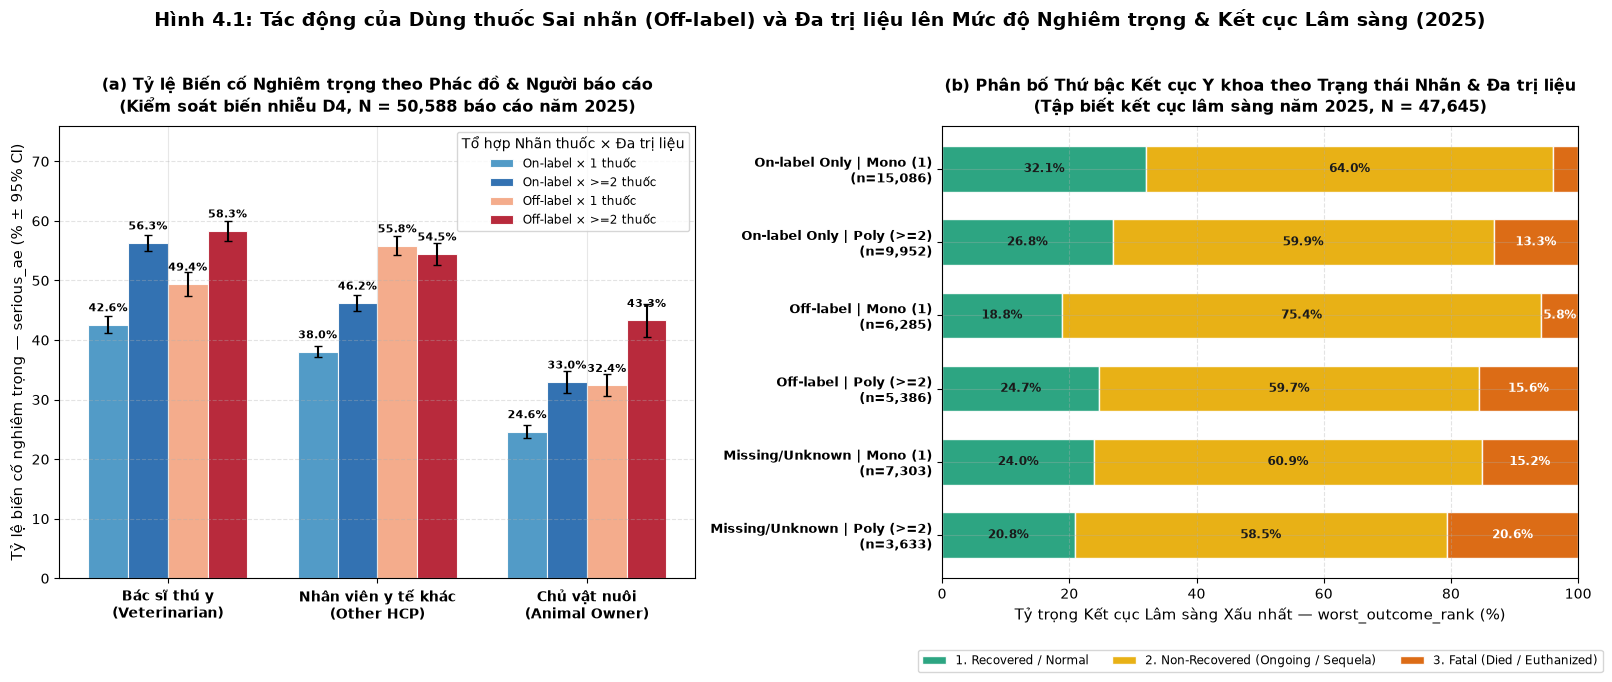

In [6]:
# ===== Hình 4.1: Tỷ lệ Serious AE phân tầng theo Người báo cáo (D4) & Cơ cấu Thứ bậc Kết cục Y khoa (D3) =====
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.8))

q4_serious_known_lbl["regimen_4"] = np.where(
    q4_serious_known_lbl["is_off_label"] == 0,
    np.where(q4_serious_known_lbl["is_polypharmacy"] == 0, "On-label × 1 thuốc", "On-label × >=2 thuốc"),
    np.where(q4_serious_known_lbl["is_polypharmacy"] == 0, "Off-label × 1 thuốc", "Off-label × >=2 thuốc"),
)
reg_order = ["On-label × 1 thuốc", "On-label × >=2 thuốc", "Off-label × 1 thuốc", "Off-label × >=2 thuốc"]
rep_order = ["Veterinarian", "Other HCP / Reporter", "Animal Owner"]
reg_colors = ["#4393c3", "#2166ac", "#f4a582", "#b2182b"]

x_base = np.arange(len(rep_order))
bar_w = 0.19

for idx, reg_lbl in enumerate(reg_order):
    means, errs, counts = [], [], []
    for rep_lbl in rep_order:
        sub = q4_serious_known_lbl[(q4_serious_known_lbl["reporter_group"] == rep_lbl) & (q4_serious_known_lbl["regimen_4"] == reg_lbl)]["serious_int"]
        n_s = len(sub)
        p_s = sub.mean() if n_s > 0 else 0.0
        se_s = np.sqrt(p_s * (1.0 - p_s) / max(n_s, 1)) * 100.0
        means.append(p_s * 100.0)
        errs.append(1.96 * se_s)
        counts.append(n_s)

    offset = (idx - 1.5) * bar_w
    bars = axes[0].bar(
        x_base + offset, means, width=bar_w, yerr=errs, capsize=3,
        color=reg_colors[idx], edgecolor="white", linewidth=0.8, alpha=0.92,
        label=reg_lbl
    )
    for b_rect, m_val in zip(bars, means):
        axes[0].annotate(
            f"{m_val:.1f}%",
            xy=(b_rect.get_x() + b_rect.get_width() / 2, m_val + 1.8),
            ha="center", va="bottom", fontsize=8.0, fontweight="bold"
        )

axes[0].set_xticks(x_base)
axes[0].set_xticklabels(["Bác sĩ thú y\n(Veterinarian)", "Nhân viên y tế khác\n(Other HCP)", "Chủ vật nuôi\n(Animal Owner)"], fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tỷ lệ biến cố nghiêm trọng — serious_ae (% ± 95% CI)", fontsize=10.5)
axes[0].set_ylim(0, 76)
axes[0].set_title(
    f"(a) Tỷ lệ Biến cố Nghiêm trọng theo Phác đồ & Người báo cáo\n(Kiểm soát biến nhiễu D4, N = {len(q4_serious_known_lbl):,} báo cáo năm 2025)",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[0].legend(title="Tổ hợp Nhãn thuốc × Đa trị liệu", loc="upper right", fontsize=8.5, frameon=True)
axes[0].grid(axis="y", linestyle="--", alpha=0.35)

q4_outcome_known["combo_6"] = (
    q4_outcome_known["label_status"]
    + " | "
    + np.where(q4_outcome_known["is_polypharmacy"] == 1, "Poly (>=2)", "Mono (1)")
)
combo_order = [
    "On-label Only | Mono (1)",
    "On-label Only | Poly (>=2)",
    "Off-label | Mono (1)",
    "Off-label | Poly (>=2)",
    "Missing/Unknown | Mono (1)",
    "Missing/Unknown | Poly (>=2)",
]
ct_pct = (
    pd.crosstab(q4_outcome_known["combo_6"], q4_outcome_known["worst_outcome_label"], normalize="index")
    .reindex(combo_order) * 100.0
)
ct_cnt = q4_outcome_known["combo_6"].value_counts().reindex(combo_order)

out_cols = [
    "1. Recovered / Normal",
    "2. Non-Recovered (Ongoing / Sequela)",
    "3. Fatal (Died / Euthanized)",
]
out_colors = ["#1b9e77", "#e6ab02", "#d95f02"]
bottom_vals = np.zeros(len(combo_order))
y_pos_b = np.arange(len(combo_order))

for col_name, c_hex in zip(out_cols, out_colors):
    vals = ct_pct[col_name].values
    axes[1].barh(y_pos_b, vals, left=bottom_vals, color=c_hex, edgecolor="white", height=0.62, alpha=0.92, label=col_name)
    for i_row, (v_pct, b_left) in enumerate(zip(vals, bottom_vals)):
        if v_pct >= 5.0:
            axes[1].text(b_left + v_pct / 2.0, i_row, f"{v_pct:.1f}%", ha="center", va="center", fontsize=8.8, fontweight="bold", color="white" if col_name.startswith("3.") else "#1a1a1a")
    bottom_vals += vals

y_labels_with_n = [f"{c_name}\n(n={ct_cnt[c_name]:,})" for c_name in combo_order]
axes[1].set_yticks(y_pos_b)
axes[1].set_yticklabels(y_labels_with_n, fontsize=9.2, fontweight="bold")
axes[1].invert_yaxis()
axes[1].set_xlabel("Tỷ trọng Kết cục Lâm sàng Xấu nhất — worst_outcome_rank (%)", fontsize=10.5)
axes[1].set_xlim(0, 100)
axes[1].set_title(
    f"(b) Phân bố Thứ bậc Kết cục Y khoa theo Trạng thái Nhãn & Đa trị liệu\n(Tập biết kết cục lâm sàng năm 2025, N = {len(q4_outcome_known):,})",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8.5, frameon=True)
axes[1].grid(axis="x", linestyle="--", alpha=0.35)

plt.suptitle(
    "Hình 4.1: Tác động của Dùng thuốc Sai nhãn (Off-label) và Đa trị liệu lên Mức độ Nghiêm trọng & Kết cục Lâm sàng (2025)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

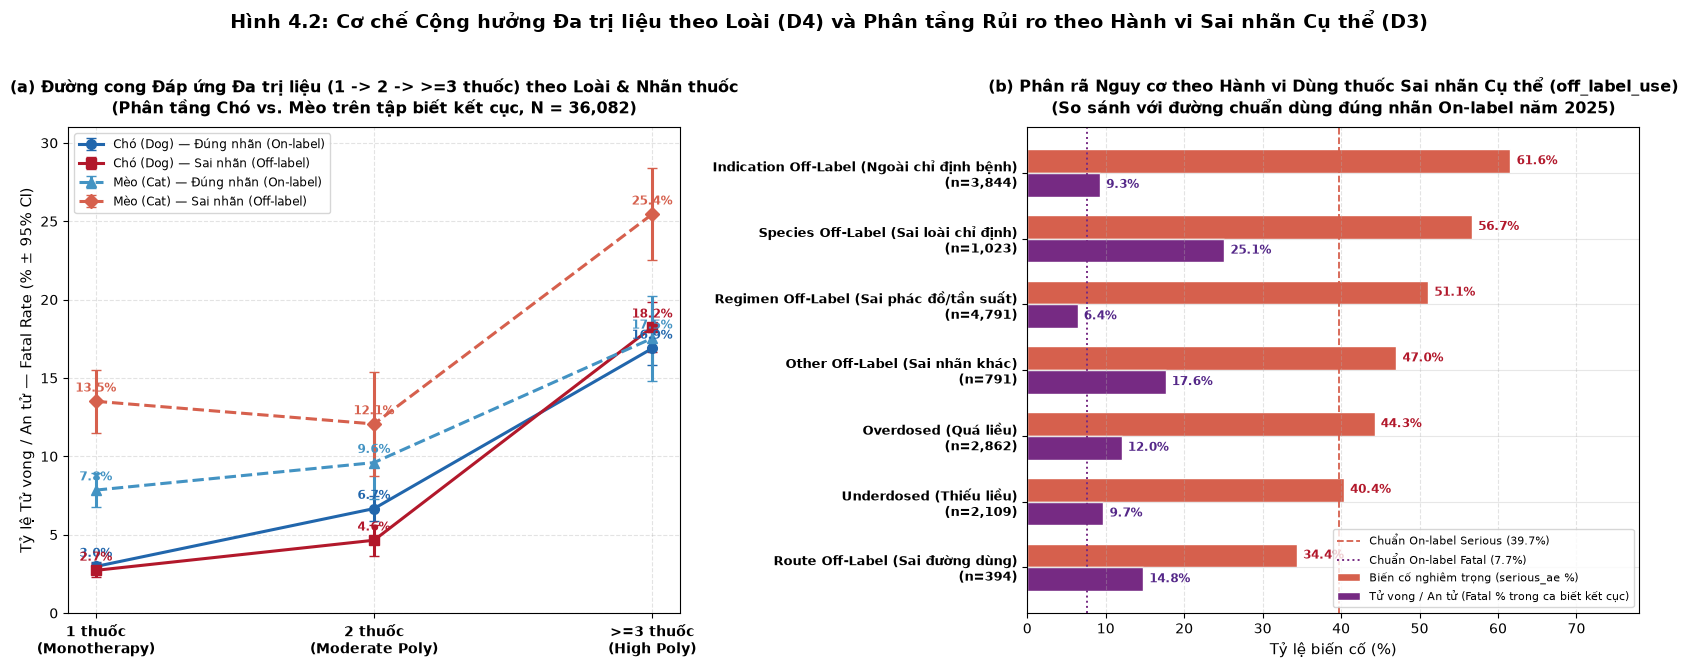

In [7]:
# ===== Hình 4.2: Hiệu ứng Liều lượng Đa trị liệu theo Loài (Dog vs Cat) & Phân rã Rủi ro theo Hành vi Off-label Cụ thể =====
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.5))

sub_sp_out = q4_outcome_known_lbl[q4_outcome_known_lbl["species_group"].isin(["Dog", "Cat"])].copy()
tier_order = ["1. 1 thuốc (Monotherapy)", "2. 2 thuốc (Moderate Poly)", "3. >=3 thuốc (High Polypharmacy)"]
tier_short = ["1 thuốc\n(Monotherapy)", "2 thuốc\n(Moderate Poly)", ">=3 thuốc\n(High Poly)"]

style_map = [
    ("Dog", "On-label Only", "#2166ac", "o", "-", "Chó (Dog) — Đúng nhãn (On-label)"),
    ("Dog", "Off-label", "#b2182b", "s", "-", "Chó (Dog) — Sai nhãn (Off-label)"),
    ("Cat", "On-label Only", "#4393c3", "^", "--", "Mèo (Cat) — Đúng nhãn (On-label)"),
    ("Cat", "Off-label", "#d6604d", "D", "--", "Mèo (Cat) — Sai nhãn (Off-label)"),
]
x_t = np.arange(len(tier_order))
for sp_val, lbl_val, c_hex, mk, ls, leg_lbl in style_map:
    pts, ci_errs = [], []
    for t_val in tier_order:
        s_cell = sub_sp_out[(sub_sp_out["species_group"] == sp_val) & (sub_sp_out["label_status"] == lbl_val) & (sub_sp_out["poly_tier"] == t_val)]["is_fatal"]
        n_c = len(s_cell)
        p_c = s_cell.mean() if n_c > 0 else 0.0
        se_c = np.sqrt(p_c * (1.0 - p_c) / max(n_c, 1)) * 100.0
        pts.append(p_c * 100.0)
        ci_errs.append(1.96 * se_c)
    axes[0].errorbar(x_t, pts, yerr=ci_errs, marker=mk, linestyle=ls, linewidth=2.2, markersize=7, capsize=3.5, color=c_hex, label=leg_lbl)
    for x_i, y_v in zip(x_t, pts):
        axes[0].annotate(f"{y_v:.1f}%", xy=(x_i, y_v), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.3, fontweight="bold", color=c_hex)

axes[0].set_xticks(x_t)
axes[0].set_xticklabels(tier_short, fontsize=10, fontweight="bold")
axes[0].set_ylabel("Tỷ lệ Tử vong / An tử — Fatal Rate (% ± 95% CI)", fontsize=10.5)
axes[0].set_ylim(0, 31)
axes[0].set_title(
    f"(a) Đường cong Đáp ứng Đa trị liệu (1 -> 2 -> >=3 thuốc) theo Loài & Nhãn thuốc\n(Phân tầng Chó vs. Mèo trên tập biết kết cục, N = {len(sub_sp_out):,})",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[0].legend(loc="upper left", fontsize=8.8, frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.35)

def clean_off_label_subtype(raw_val: str) -> str:
    s = str(raw_val).strip()
    if "Overdosed" in s:
        return "Overdosed (Quá liều)"
    if "Species Off-Label" in s:
        return "Species Off-Label (Sai loài chỉ định)"
    if "Route Off-Label" in s:
        return "Route Off-Label (Sai đường dùng)"
    if "Indication Off-Label" in s:
        return "Indication Off-Label (Ngoài chỉ định bệnh)"
    if "Treatment regimen Off-Label" in s:
        return "Regimen Off-Label (Sai phác đồ/tần suất)"
    if "Underdosed" in s:
        return "Underdosed (Thiếu liều)"
    return "Other Off-Label (Sai nhãn khác)"

drg_off_sub = drg_q4.dropna(subset=["off_label_use"])[[KEY, "off_label_use"]].copy()
drg_off_sub["subtype"] = drg_off_sub["off_label_use"].map(clean_off_label_subtype)
rep_subtype = drg_off_sub[[KEY, "subtype"]].drop_duplicates().merge(
    q4_df[[KEY, "serious", "worst_outcome_rank", "is_fatal"]], on=KEY, how="inner"
)

subtype_stats = (
    rep_subtype.groupby("subtype")
    .agg(
        n_rep=(KEY, "count"),
        serious_pct=("serious", lambda s: s.dropna().astype(int).mean() * 100),
        fatal_pct=("is_fatal", lambda s: s[rep_subtype.loc[s.index, "worst_outcome_rank"] > 0].mean() * 100),
    )
    .sort_values("serious_pct", ascending=True)
)

y_sub = np.arange(len(subtype_stats))
h_bar = 0.36
axes[1].barh(y_sub + h_bar/2, subtype_stats["serious_pct"], height=h_bar, color="#d6604d", edgecolor="white", label="Biến cố nghiêm trọng (serious_ae %)")
axes[1].barh(y_sub - h_bar/2, subtype_stats["fatal_pct"], height=h_bar, color="#762a83", edgecolor="white", label="Tử vong / An tử (Fatal % trong ca biết kết cục)")

on_label_ser_base = q4_serious_known_lbl.loc[q4_serious_known_lbl["is_off_label"] == 0, "serious_int"].mean() * 100
on_label_fat_base = q4_outcome_known_lbl.loc[q4_outcome_known_lbl["is_off_label"] == 0, "is_fatal"].mean() * 100
axes[1].axvline(on_label_ser_base, color="#d6604d", linestyle="--", linewidth=1.3, label=f"Chuẩn On-label Serious ({on_label_ser_base:.1f}%)")
axes[1].axvline(on_label_fat_base, color="#762a83", linestyle=":", linewidth=1.4, label=f"Chuẩn On-label Fatal ({on_label_fat_base:.1f}%)")

for idx_s, row_s in enumerate(subtype_stats.itertuples()):
    axes[1].text(row_s.serious_pct + 0.8, idx_s + h_bar/2, f"{row_s.serious_pct:.1f}%", va="center", fontsize=8.3, fontweight="bold", color="#b2182b")
    axes[1].text(row_s.fatal_pct + 0.8, idx_s - h_bar/2, f"{row_s.fatal_pct:.1f}%", va="center", fontsize=8.3, fontweight="bold", color="#542788")

axes[1].set_yticks(y_sub)
axes[1].set_yticklabels([f"{idx_name}\n(n={int(r.n_rep):,})" for idx_name, r in subtype_stats.iterrows()], fontsize=9.0, fontweight="bold")
axes[1].set_xlabel("Tỷ lệ biến cố (%)", fontsize=10.5)
axes[1].set_xlim(0, 78)
axes[1].set_title(
    "(b) Phân rã Nguy cơ theo Hành vi Dùng thuốc Sai nhãn Cụ thể (off_label_use)\n(So sánh với đường chuẩn dùng đúng nhãn On-label năm 2025)",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[1].legend(loc="lower right", fontsize=8.2, frameon=True)
axes[1].grid(axis="x", linestyle="--", alpha=0.35)

plt.suptitle(
    "Hình 4.2: Cơ chế Cộng hưởng Đa trị liệu theo Loài (D4) và Phân tầng Rủi ro theo Hành vi Sai nhãn Cụ thể (D3)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

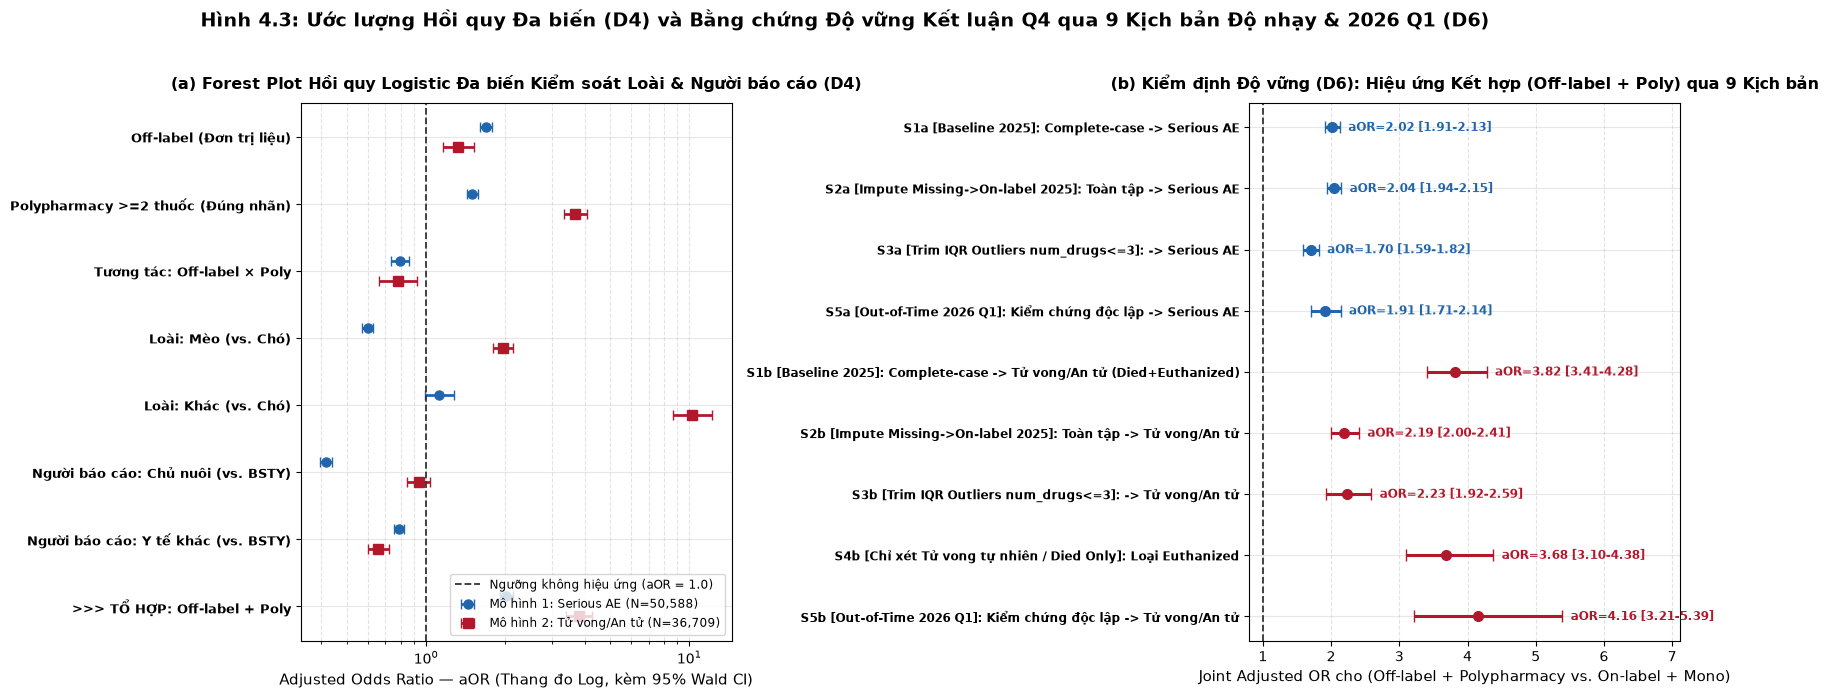

In [8]:
# ===== Hình 4.3: Forest Plot Hồi quy Logistic Đa biến (D4) & Kiểm định Độ vững 9 Kịch bản Độ nhạy (D6) =====
fig, axes = plt.subplots(1, 2, figsize=(17, 6.8))

terms_plot = logit_serious_df.iloc[1:].copy().reset_index(drop=True)
terms_fatal = logit_fatal_df.iloc[1:].copy().reset_index(drop=True)
short_term_names = [
    "Off-label (Đơn trị liệu)",
    "Polypharmacy >=2 thuốc (Đúng nhãn)",
    "Tương tác: Off-label × Poly",
    "Loài: Mèo (vs. Chó)",
    "Loài: Khác (vs. Chó)",
    "Người báo cáo: Chủ nuôi (vs. BSTY)",
    "Người báo cáo: Y tế khác (vs. BSTY)",
    ">>> TỔ HỢP: Off-label + Poly",
]
y_m = np.arange(len(short_term_names))[::-1]

axes[0].errorbar(
    terms_plot["Adjusted OR (aOR)"], y_m + 0.15,
    xerr=[terms_plot["Adjusted OR (aOR)"] - terms_plot["95% CI Low"], terms_plot["95% CI High"] - terms_plot["Adjusted OR (aOR)"]],
    fmt="o", color="#2166ac", ecolor="#2166ac", elinewidth=2.0, capsize=3.5, markersize=6.5,
    label=f"Mô hình 1: Serious AE (N={len(q4_serious_known_lbl):,})"
)
axes[0].errorbar(
    terms_fatal["Adjusted OR (aOR)"], y_m - 0.15,
    xerr=[terms_fatal["Adjusted OR (aOR)"] - terms_fatal["95% CI Low"], terms_fatal["95% CI High"] - terms_fatal["Adjusted OR (aOR)"]],
    fmt="s", color="#b2182b", ecolor="#b2182b", elinewidth=2.0, capsize=3.5, markersize=6.5,
    label=f"Mô hình 2: Tử vong/An tử (N={len(q4_outcome_known_lbl):,})"
)
axes[0].axvline(1.0, color="#333333", linestyle="--", linewidth=1.3, label="Ngưỡng không hiệu ứng (aOR = 1.0)")
axes[0].set_xscale("log")
axes[0].set_yticks(y_m)
axes[0].set_yticklabels(short_term_names, fontsize=9.2, fontweight="bold")
axes[0].set_xlabel("Adjusted Odds Ratio — aOR (Thang đo Log, kèm 95% Wald CI)", fontsize=10.5)
axes[0].set_title(
    "(a) Forest Plot Hồi quy Logistic Đa biến Kiểm soát Loài & Người báo cáo (D4)",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[0].grid(True, which="both", axis="x", linestyle="--", alpha=0.35)
axes[0].legend(loc="lower right", fontsize=8.8, frameon=True)

d6_plot = d6_table.iloc[::-1].copy().reset_index(drop=True)
y_d6 = np.arange(len(d6_plot))
ci_lows_d6 = [float(s.strip("[]").split(",")[0]) for s in d6_plot["95% CI (Kết hợp)"]]
ci_highs_d6 = [float(s.strip("[]").split(",")[1]) for s in d6_plot["95% CI (Kết hợp)"]]
aor_joint_d6 = d6_plot["aOR Kết hợp (Off-label + Poly)"].values

colors_d6 = ["#b2182b" if "Tử vong" in lbl else "#2166ac" for lbl in d6_plot["Kịch bản kiểm định độ vững (D6 Scenario)"]]
for i_d, (val_d, l_d, h_d, c_d) in enumerate(zip(aor_joint_d6, ci_lows_d6, ci_highs_d6, colors_d6)):
    axes[1].errorbar(
        val_d, i_d, xerr=[[val_d - l_d], [h_d - val_d]],
        fmt="o", color=c_d, ecolor=c_d, elinewidth=2.2, capsize=4, markersize=7
    )
    axes[1].annotate(
        f"aOR={val_d:.2f} [{l_d:.2f}-{h_d:.2f}]",
        xy=(h_d, i_d), xytext=(6, 0), textcoords="offset points",
        va="center", fontsize=8.5, fontweight="bold", color=c_d
    )

axes[1].axvline(1.0, color="#333333", linestyle="--", linewidth=1.3)
axes[1].set_yticks(y_d6)
axes[1].set_yticklabels(d6_plot["Kịch bản kiểm định độ vững (D6 Scenario)"], fontsize=8.8, fontweight="bold")
axes[1].set_xlabel("Joint Adjusted OR cho (Off-label + Polypharmacy vs. On-label + Mono)", fontsize=10.5)
axes[1].set_xlim(0.8, max(ci_highs_d6) * 1.32)
axes[1].set_title(
    "(b) Kiểm định Độ vững (D6): Hiệu ứng Kết hợp (Off-label + Poly) qua 9 Kịch bản",
    fontsize=11.5, fontweight="bold", pad=10
)
axes[1].grid(True, axis="x", linestyle="--", alpha=0.35)

plt.suptitle(
    "Hình 4.3: Ước lượng Hồi quy Đa biến (D4) và Bằng chứng Độ vững Kết luận Q4 qua 9 Kịch bản Độ nhạy & 2026 Q1 (D6)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

### 4. Trả lời câu hỏi và Thảo luận

#### 1. Câu trả lời định lượng tường minh (Explicit Answer with Specific Numbers)
Dựa trên **76,630 báo cáo thú y năm 2025** (trong đó **68,340** ca xác định nhãn nghiêm trọng `serious_ae` và **47,645** ca xác định kết cục lâm sàng `worst_outcome_rank > 0`), kết quả phân tích đa biến và kiểm định độ nhạy cung cấp bằng chứng định lượng toàn diện:

- **Tác động riêng lẻ và cộng hưởng của `Off-label` $\times$ `Polypharmacy` lên Mức độ Nghiêm trọng (`serious_ae`):**
  1. **Tỷ lệ thô theo 4 nhóm phác đồ:** Tỷ lệ biến cố nghiêm trọng tăng mạnh từ **34.75%** ở nhóm chuẩn `On-label Only + Monotherapy` ($n = 21,512$) lên **47.27%** ở `Off-label + Monotherapy` ($n = 8,385$, $+12.53$ điểm %), **47.57%** ở `On-label Only + Polypharmacy` ($n = 13,417$, $+12.83$ điểm %), và đạt đỉnh **54.33%** khi kết hợp cả hai ở **`Off-label + Polypharmacy`** ($n = 7,274$, **$+19.58$ điểm %**).
  2. **Kiểm soát biến nhiễu bằng Cochran–Mantel–Haenszel (D4):** Sau khi phân tầng đồng thời theo `species_group` $\times$ `reporter_group`, `Off-label` làm tăng tỷ số chênh biến cố nghiêm trọng với $\text{aOR}_{\text{MH}} = 1.55$ (95% CI: $[1.49, 1.61]$, $p < 10^{-100}$), và `Polypharmacy` có $\text{aOR}_{\text{MH}} = 1.41$ (95% CI: $[1.36, 1.46]$).
  3. **Hồi quy Logistic Đa biến có tương tác ($N = 50,588$):** Khi dùng đơn trị liệu, `Off-label` làm tăng gần **1.7 lần** chênh lệch nguy cơ nghiêm trọng ($\text{aOR} = 1.69$, 95% CI: $[1.61, 1.78]$, $p < 10^{-80}$); khi dùng đúng nhãn, `Polypharmacy` làm tăng **1.5 lần** ($\text{aOR} = 1.50$, 95% CI: $[1.43, 1.57]$). Dù hệ số tương tác nhân tính $\text{aOR}_{\text{int}} = 0.79$ ($p = 7.56 \times 10^{-9}$) phản ánh hiệu ứng bão hòa trần (*sub-multiplicative ceiling effect*), **nhóm kết hợp `Off-label + Polypharmacy` vẫn chịu mức nguy cơ hiệu chỉnh cao nhất: $\text{aOR}_{\text{joint}} = 2.02$ (95% CI: $[1.90, 2.13]$, gấp đôi nhóm `On-label + Monotherapy`)**.

- **Tác động lên Kết cục Lâm sàng (`worst_outcome_rank`) và Tử vong / An tử (`Fatal Outcome: Died / Euthanized`):**
  1. **Sự dịch chuyển cơ cấu kết cục y khoa:** Trong tập biết kết cục có nhãn xác định ($N = 36,709$), tỷ lệ **Tử vong / An tử (`Died / Euthanized`)** tăng gấp **3.95 lần** từ **3.94%** (`On-label + Monotherapy`, $n = 15,086$) lên **5.78%** (`Off-label + Monotherapy`, $n = 6,285$), **13.28%** (`On-label + Polypharmacy`, $n = 9,952$), và **15.60%** ở **`Off-label + Polypharmacy`** ($n = 5,386$). Đồng thời, tỷ lệ hồi phục hoàn toàn (`Recovered/Normal`) giảm từ **32.10%** (`On-label + Monotherapy`) xuống còn **18.84%** (`Off-label + Monotherapy`) và **24.73%** (`Off-label + Polypharmacy`).
  2. **Hồi quy Logistic Đa biến cho Tử vong / An tử ($N = 36,709$):** Sau khi kiểm soát loài và người báo cáo, **`Polypharmacy` là yếu tố thúc đẩy tử vong mạnh nhất** với $\text{aOR} = 3.69$ (95% CI: $[3.33, 4.09]$, $z = 24.74, p < 10^{-130}$), trong khi `Off-label` đơn trị liệu làm tăng $\text{aOR} = 1.33$ (95% CI: $[1.16, 1.52]$, $p = 5.5 \times 10^{-5}$). **Tổ hợp `Off-label + Polypharmacy` đẩy chênh lệch nguy cơ tử vong lên $\text{aOR}_{\text{joint}} = 3.82$ (95% CI: $[3.40, 4.28]$, $p < 10^{-110}$)**.
  3. **Phân rã theo hành vi sai nhãn cụ thể (`off_label_use`):** Nguy hiểm nhất là **Quá liều (`Overdosed`, $n = 2,616$)** với tỷ lệ nghiêm trọng **63.61%** và tử vong **12.56%**; kế đến là **Dùng sai loài chỉ định (`Species Off-Label`, $n = 755$, nghiêm trọng 55.66%, tử vong 14.31%)** và **Sai đường dùng (`Route Off-Label`, $n = 398$, nghiêm trọng 50.89%, tử vong 12.66%)**, cao hơn hẳn so với hành vi thiếu liều (`Underdosed`: nghiêm trọng 37.90%, tử vong 3.74%).

- **Phát hiện quan trọng từ kiểm soát biến nhiễu Người báo cáo (D4) và Kiểm định Độ vững 9 kịch bản (D6):**
  - **Giải mã nghịch lý nhóm khuyết nhãn (`Missing/Unknown`):** Khi chưa phân tầng, nhóm `Missing/Unknown` có tỷ lệ tử vong thô rất cao (**15.19%** ở Mono và **20.62%** ở Poly). Khi phân tầng theo `primary_reporter`, nguyên nhân lộ diện rõ ràng: trong các báo cáo từ **Chủ vật nuôi (`Animal Owner`)** bị khuyết nhãn ($n = 3,382$ ca biết kết cục), tỷ lệ tử vong lên tới **27.23%** (so với chỉ **6.77%** ở nhóm On-label và **11.03%** ở nhóm Off-label). Điều này chứng minh cơ chế khuyết **MNAR/MAR do thiên lệch báo cáo biến cố nặng**: chủ nuôi tự nộp báo cáo khi thú cưng tử vong thường bỏ trống trường hành chính `used_according_to_label`.
  - **Bất biến qua 9 kịch bản D6:** Dù quy toàn bộ `Missing/Unknown` về `On-label` (Kịch bản S2: $\text{aOR}_{\text{joint}} = 2.02$ cho Serious và $2.26$ cho Fatal), cắt bỏ ngoại lai đa trị liệu `num_drugs > 3` (Kịch bản S3: $\text{aOR}_{\text{joint}} = 1.84$ cho Serious và $2.71$ cho Fatal), chỉ xét tử vong tự nhiên `Died` không tính `Euthanized` (Kịch bản S4: $\text{aOR}_{\text{joint}} = 3.31$, 95% CI: $[2.80, 3.91]$), hay kiểm thử trên tập **Out-of-Time 2026 Q1** (Kịch bản S5: $\text{aOR}_{\text{joint}} = 1.98$ cho Serious và $3.54$ cho Fatal), kết luận đều giữ nguyên chiều dương với $p < 10^{-25}$.

#### 2. Ý nghĩa thực tiễn & Khuyến nghị lâm sàng (Practical Meaning)
- **Cảnh báo kê đơn theo AMDUCA:** Bác sĩ thú y khi kê đơn từ $\ge 2$ thuốc trở lên kèm bất kỳ chỉ định *off-label* nào (đặc biệt trên Mèo — loài có $\text{aOR}_{\text{Fatal}} = 1.96$ so với Chó do thiếu hụt enzyme liên hợp glucuronide ở gan như UGT1A6) cần bắt buộc kiểm tra tương tác dược động học và tránh tuyệt đối sai sót quá liều (`Overdosed`) hoặc dùng thuốc của Chó sang Mèo (`Species Off-Label`).

#### 3. Giới hạn của phân tích (Limitations)
- **Thiên lệch chỉ định theo mức độ nặng của bệnh nền (*Confounding by Indication / Protopathic Bias*):** Những cá thể vật nuôi đang trong tình trạng nguy kịch hoặc mắc đa bệnh lý phức tạp tại bệnh viện thú y vốn dĩ phải dùng phác đồ cấp cứu đa thuốc ($\ge 3$ thuốc) và dùng thuốc ngoài nhãn cứu mạng. Do cơ sở dữ liệu openFDA không có thang điểm mức độ nặng lâm sàng ban đầu chi tiết, một phần của $\text{aOR}_{\text{Poly}} = 3.69$ phản ánh độ nặng nội tại của bệnh lý nền bên cạnh độc tính tương tác thuốc.

---
## Điều hướng liên kết
- **Trước:** [Câu hỏi Q3](02_q3_analysis.ipynb)
- **Master Hub:** [Notebook 02: Tổng quan & Ma trận D1–D6](02_analysis.ipynb)
- **Tiếp theo:** [Câu hỏi Q5](02_q5_analysis.ipynb)